# vertical_resonance: test particles at a satellite's vertical resonance (epi_int_3d)

A zero-mass ring, 81 circular streamlines of 6 particles spanning 1 ≤ r ≤ 1.04, under a vertical Fourier
satellite (`fast/satellite.py`). Its m = 2 inner vertical resonance is at r_V = 1.02, mid-ring. The satellite
(i_s = 0.01) grows as M_s(t) = 10⁻⁶(1 − e^{−t/τ}), τ = 10⁴, and the run lasts 2×10⁴ orbits (t = 1.26×10⁵, 12.6τ).

Expectations (notes/equations.md B6, B11; notes/phase2c/bending_wave_theory.md):

1. Starting from z = v_z = 0, each particle's z(t) is the exact solution B11. Its vertical oscillation grows
   with the satellite's mass and settles into the forced response B6, z = F_z/(ν² − ω_m²), which changes sign
   across r_V.
2. A free oscillation at ν remains, never decaying, of relative size ~1/(τ|ν − ω_m|). It is small except near r_V.
3. The streamline at r_V grows without bound.
4. Averaged over the last 10⁴ orbits, when the satellite is fully grown, each streamline's inclination is the
   forced inclination B12, i_f ≃ (M_s/M_p) i_s β_V² b_{3/2}^{(m)}(β_V)/[6(m−1)|x|] near r_V (Shu 1984's L_V/x).

Make the output with `uv run python tools/run_simulations.py tests/vertical_resonance` (about 30 s).

In [1]:
import sys
sys.path.insert(0, '../../source')
sys.path.insert(0, '../../fast')
sys.path.insert(0, '..')
import numpy as np
import matplotlib.pyplot as plt
from vertical_analysis import load3d, forced_vertical
plt.rcParams.update({'font.size': 13})
p, o = load3d('.')
sat, f = forced_vertical(p, o)
orbits = o['times']/(2*np.pi)
for k in ('number_of_streamlines', 'particles_per_streamline', 'dt', 'J2', 'Rp', 'total_ring_mass'):
    print(k, '=', p[k])
for k, v in sat.summary().items():
    print(k, '=', v)

number_of_streamlines = 81
particles_per_streamline = 6
dt = 0.5
J2 = 0.01
Rp = 0.5
total_ring_mass = 0.0
resonance = vertical
m = 2
mass_final = 1e-06
time_grow = 10000.0
r = 2.125201719667671
t = 0.0
inclination = 0.01
node = 0.0
Omega_a = 0.32290887596468926
nu_a = 0.32317665122950057
Omega_p = 0.48449720157943954
r_V = 1.0200000000000002
beta_V = 0.47995443941175764
b_32 = 1.371036763995872
A_V_per_mass = 0.0015178148146808492
A_V_final = 1.5178148146808491e-09
D_V = 2.8303757359671824


## 1: vertical amplitude of each streamline versus time, against B11

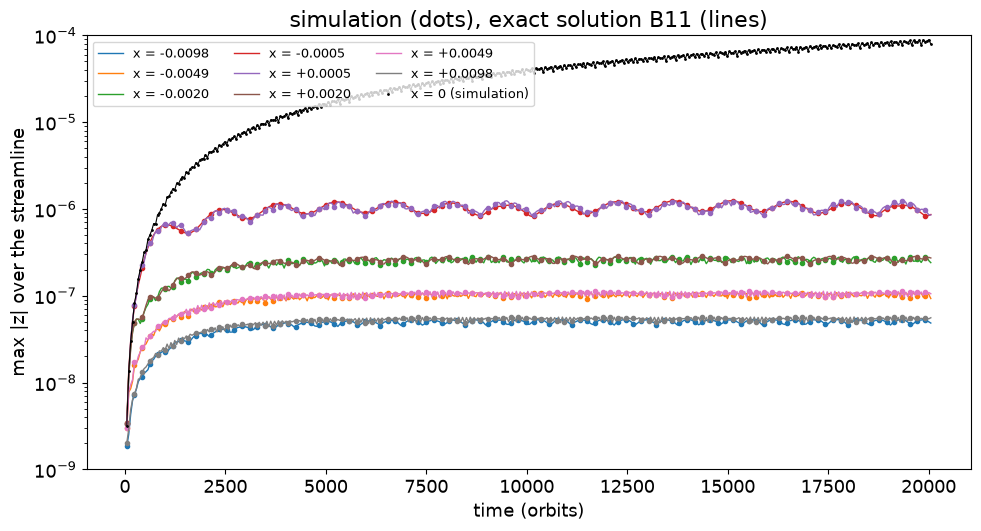

In [2]:
amp, amp_th = np.abs(o['z']).max(axis=2), np.abs(f['z']).max(axis=2)
picks = [20, 30, 36, 39, 41, 44, 50, 60]
fig, ax = plt.subplots(figsize=(10, 5.5))
for j in picks:
    l, = ax.plot(orbits, amp_th[:, j], lw=1, label=f"x = {f['x'][j]:+.4f}")
    ax.plot(orbits[::4], amp[::4, j], 'o', ms=3, color=l.get_color())
ax.plot(orbits, amp[:, 40], 'k.', ms=2, label='x = 0 (simulation)')
ax.plot(orbits, amp_th[:, 40], 'k-', lw=0.8)
ax.set_yscale('log'); ax.set_ylim(1e-9, 1e-4)
ax.set_xlabel('time (orbits)'); ax.set_ylabel('max |z| over the streamline')
ax.set_title('simulation (dots), exact solution B11 (lines)')
ax.legend(fontsize=9, ncol=3, loc='upper left')
plt.tight_layout()

## 2: time-averaged inclination versus time-averaged distance from resonance, over the last 10⁴ orbits

The curve is the forced inclination B12, Shu (1984)'s L_V/x term (the paper's Appendix E). The printout also
compares with the exact forced inclination, A_V/(a|ν² − ω_m²|) averaged over phase, which B12 approximates to first
order in x.

<i>/forced - 1 away from r_V: median 2.8e-04, max 2.0e-03 (at x = -0.0142)
<i>/B12 away from r_V: 0.964 to 1.033
B12/forced - 1 at |x| = 0.02: +0.037, -0.032
z in phase with the forced response B6, all streamlines except r_V: True


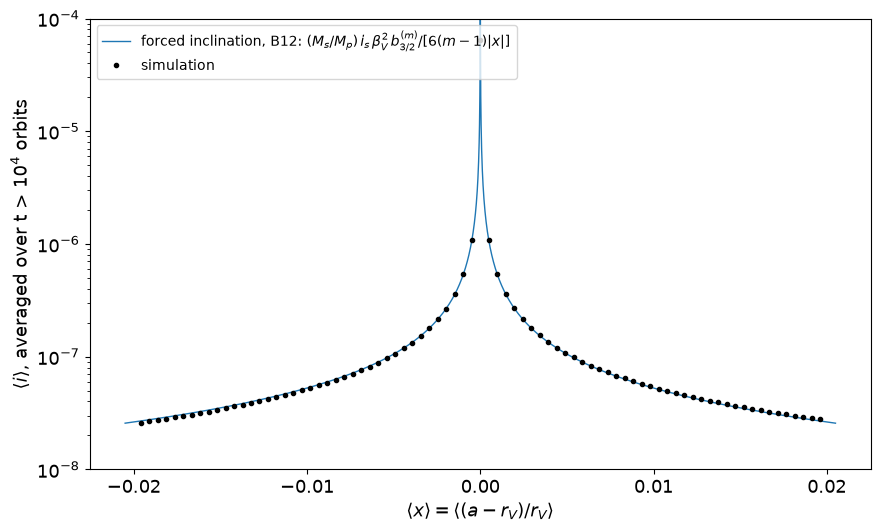

In [3]:
x = f['x']
late = orbits > 1.0e4                                                   #the satellite is fully grown
i_avg = o['inc'][late].mean(axis=(0, 2))                                #time and particle average, per streamline
x_avg = ((o['a'][late] - sat.r_V)/sat.r_V).mean(axis=(0, 2))
#theory: the forced oscillation z = h sin(omega_m t + phi), h = A_V/(nu^2 - omega_m^2) (B6), whose V3 inclination
#(h/a) [sin^2 + (omega_m/nu)^2 cos^2]^(1/2), averaged over phase
from vertical_analysis import nu_a
from helper_fns import Omega
a_avg = o['a'][late].mean(axis=(0, 2))
nu = nu_a(p['J2'], p['Rp'], a_avg)
w = sat.m*(Omega(p['J2'], p['Rp'], a_avg) - sat.Omega_p)
A_V = sat.mass_final*sat.A_V_per_mass
phase = np.linspace(0, 2*np.pi, 2001)[:-1]
shape = np.sqrt(np.sin(phase)[:, None]**2 + ((w/nu)*np.cos(phase)[:, None])**2).mean(axis=0)
i_forced = A_V/np.abs(nu**2 - w**2)/a_avg*shape
xs = np.linspace(-0.0205, 0.0205, 4000)                         #even: skips x = 0
i_B12 = sat.mass_final*sat.inclination*sat.beta_V**2*sat.b/(6*(sat.m - 1)*np.abs(xs))   #B12, Keplerian, near r_V
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.plot(xs, i_B12, 'C0-', lw=1, label=r'forced inclination, B12: $(M_s/M_p)\,i_s\,\beta_V^2\,b_{3/2}^{(m)}/[6(m-1)|x|]$')
ax.plot(x_avg, i_avg, 'k.', ms=6, label='simulation')
ax.set_yscale('log'); ax.set_ylim(1e-8, 1e-4)
ax.set_xlabel(r'$\langle x\rangle = \langle(a - r_V)/r_V\rangle$'); ax.set_ylabel(r'$\langle i\rangle$, averaged over t > 10$^4$ orbits')
ax.legend(fontsize=10, loc='upper left')
plt.tight_layout()
ok = np.abs(x_avg) > 1e-6
rel = i_avg[ok]/i_forced[ok] - 1
print(f'<i>/forced - 1 away from r_V: median {np.median(np.abs(rel)):.1e}, max {np.abs(rel).max():.1e}'
      f' (at x = {x_avg[ok][np.argmax(np.abs(rel))]:+.4f})')
i_B12_x = sat.mass_final*sat.inclination*sat.beta_V**2*sat.b/(6*(sat.m - 1)*np.abs(x_avg[ok]))
print(f'<i>/B12 away from r_V: {(i_avg[ok]/i_B12_x).min():.3f} to {(i_avg[ok]/i_B12_x).max():.3f}')
print(f'B12/forced - 1 at |x| = 0.02: {np.interp(-0.0196, xs, i_B12)/np.interp(-0.0196, x_avg, i_forced) - 1:+.3f},'
      f' {np.interp(0.0196, xs, i_B12)/np.interp(0.0196, x_avg, i_forced) - 1:+.3f}')
#the sign: z is in phase with the forcing outside r_V and opposite inside
sgn = np.sign(np.sum(o['z'][-1]*f['forced'][-1], axis=1))
print('z in phase with the forced response B6, all streamlines except r_V:', bool((np.delete(sgn, 40) > 0).all()))

## 3: how closely the simulation follows B11, and how far it is from pure forcing at the end

max |z - B11| = 3.66e-11 (absolute); relative: resonant streamline 4.1e-07, others up to 1.3e-03


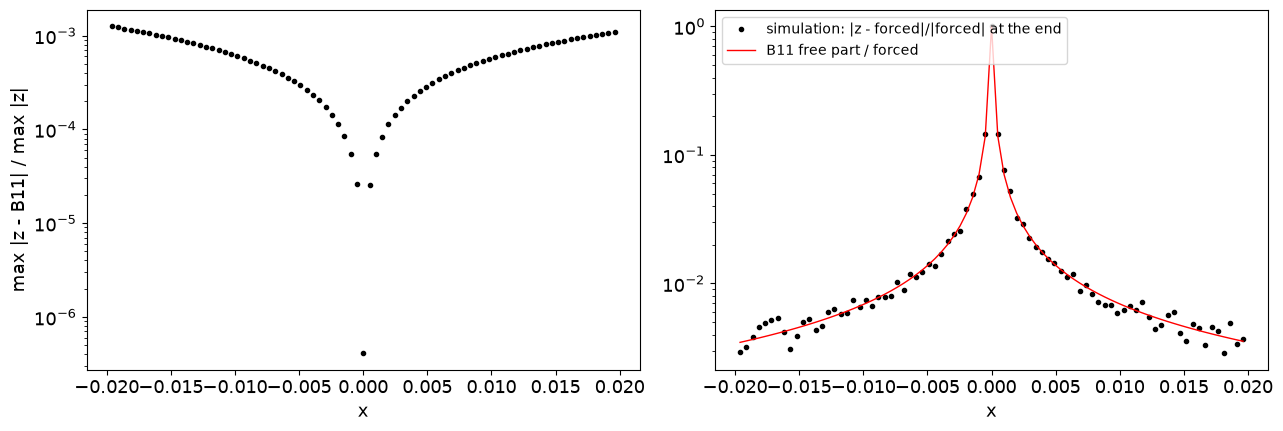

In [4]:
err = np.abs(o['z'] - f['z']).max(axis=(0, 2))
off = np.abs(o['z'][-1] - f['forced'][-1]).max(axis=1)/np.abs(f['forced'][-1]).max(axis=1)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(x, err/np.abs(f['z']).max(axis=(0, 2)), 'k.')
ax[0].set_yscale('log'); ax[0].set_xlabel('x'); ax[0].set_ylabel('max |z - B11| / max |z|')
ax[1].plot(x, off, 'k.', label='simulation: |z - forced|/|forced| at the end')
ax[1].plot(x, f['free_over_forced'][0].max(axis=1), 'r-', lw=1, label='B11 free part / forced')
ax[1].set_yscale('log'); ax[1].set_xlabel('x'); ax[1].legend(fontsize=10, loc='upper left')
plt.tight_layout()
print(f'max |z - B11| = {err.max():.2e} (absolute); relative: resonant streamline {err[40]/np.abs(f["z"][:, 40]).max():.1e},'
      f' others up to {np.delete(err/np.abs(f["z"]).max(axis=(0, 2)), 40).max():.1e}')

The simulation follows B11 to about 3×10⁻¹¹ in z everywhere. That is the leapfrog's O(dt²) error in the
non-resonant part of the response, so relative to |z| it grows with |x|, up to 1.3×10⁻³ at the ring's edges.
The streamline at r_V, where ν − ω_m ~ 10⁻¹⁴, agrees to 10⁻⁶. At the end, every streamline sits on the forced
response B6, off by just B11's free part, which never decays.

Averaged over the last 10⁴ orbits, each streamline's inclination is the forced inclination to a median 3×10⁻⁴
(at most 2×10⁻³), even beside r_V, since the free part averages away (Fig. 2). The near-resonance form B12 is
within 4% of the exact forced inclination out to |x| = 0.02.